In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, roc_curve, roc_auc_score, log_loss,
    mean_absolute_error, r2_score
)
from sklearn.datasets import make_regression

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 1. Load and explore the dataset

In [4]:
df = pd.read_csv("urban_beehive_health_dataset.csv")
display(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("\nColony stress counts (0 = no stress flag, 1 = stress flag):")
display(df["colony_stress"].value_counts().sort_index())


,observation_id,temperature_c,humidity_pct,forage_distance_km,pesticide_exposure_index,colony_strength_pct,brood_temperature_variance,queen_age_months,water_distance_km,site_type,season,colony_stress
0,HIVE-0001,24.99,39.21,3.31,11.71,82.03,0.570,36,0.33,Urban rooftop,Spring,0
1,HIVE-0002,35.28,68.89,5.23,21.95,66.95,0.429,31,1.75,Suburban yard,Summer,1
2,HIVE-0003,28.90,47.53,1.70,32.95,60.84,0.344,29,0.61,Suburban yard,Spring,0
3,HIVE-0004,32.63,49.72,3.53,11.65,50.70,0.190,16,1.63,Suburban yard,Autumn,0
4,HIVE-0005,32.85,71.28,8.27,50.70,67.99,1.010,26,2.56,Rural edge,Spring,1


Dataset shape: (1350, 12)

Missing values:


,missing_values
observation_id,0
temperature_c,0
humidity_pct,0
forage_distance_km,0
pesticide_exposure_index,0
colony_strength_pct,0
brood_temperature_variance,0
queen_age_months,0
water_distance_km,0
site_type,0



Colony stress counts (0 = no stress flag, 1 = stress flag):


,count
colony_stress,
0,961
1,389


## 2. Prepare data and train a classification model

In [5]:
# Exclude the observation ID because it is only an identifier.
X = df.drop(columns=["observation_id", "colony_stress"])
y = df["colony_stress"]

numeric_features = [
    "temperature_c", "humidity_pct", "forage_distance_km",
    "pesticide_exposure_index", "colony_strength_pct",
    "brood_temperature_variance", "queen_age_months",
    "water_distance_km"
]
categorical_features = ["site_type", "season"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
y_prob = classifier.predict_proba(X_test)[:, 1]


## 3. Calculate classification metrics

In [6]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
model_log_loss = log_loss(y_test, classifier.predict_proba(X_test), labels=[0, 1])

print("CLASSIFICATION MODEL EVALUATION")
print("=" * 42)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nConfusion matrix (rows = actual; columns = predicted):")
display(pd.DataFrame(
    cm,
    index=["Actual no stress (0)", "Actual stress (1)"],
    columns=["Predicted no stress (0)", "Predicted stress (1)"]
))
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"Log-loss  : {model_log_loss:.4f}")


CLASSIFICATION MODEL EVALUATION
Accuracy  : 0.7148 (71.48%)

Confusion matrix (rows = actual; columns = predicted):


,Predicted no stress (0),Predicted stress (1)
Actual no stress (0),173,19
Actual stress (1),58,20


Precision : 0.5128
Recall    : 0.2564
ROC-AUC   : 0.7431
Log-loss  : 0.5325


## 4. Confusion matrix visualization

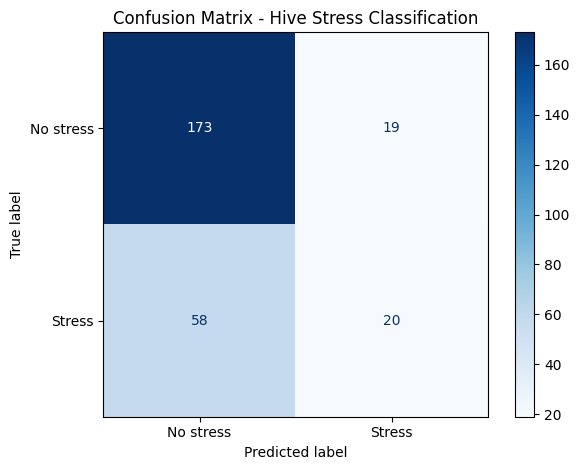

In [7]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No stress", "Stress"]
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Hive Stress Classification")
plt.tight_layout()
plt.show()


## 5. ROC curve

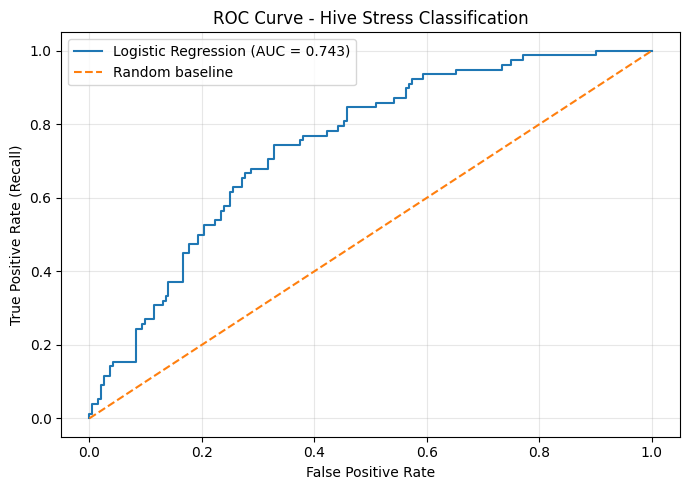

In [8]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Hive Stress Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Regression metrics and error distribution

To demonstrate regression metrics properly, this section creates a separate synthetic numeric target for estimated hive honey yield. The numeric regression data is simulated and separate from the classification target; this avoids incorrectly applying regression metrics to a binary stress label.

In [9]:
# Create a synthetic regression target: illustrative honey yield index (kg).
# It is simulated for demonstrating regression metrics, not measured field data.
rng = np.random.default_rng(RANDOM_STATE)
X_reg = df[numeric_features].to_numpy()
honey_yield = (
    18
    + 0.22 * df["colony_strength_pct"].to_numpy()
    - 0.16 * df["pesticide_exposure_index"].to_numpy()
    - 0.8 * df["brood_temperature_variance"].to_numpy()
    - 0.7 * df["forage_distance_km"].to_numpy()
    + 0.15 * df["humidity_pct"].to_numpy()
    + rng.normal(0, 5, len(df))
)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, honey_yield, test_size=0.20, random_state=RANDOM_STATE
)
regressor = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
regressor.fit(X_train_r, y_train_r)
y_pred_r = regressor.predict(X_test_r)

mad = mean_absolute_error(y_test_r, y_pred_r)
r_squared = r2_score(y_test_r, y_pred_r)
errors = y_test_r - y_pred_r

print("REGRESSION MODEL EVALUATION")
print("=" * 42)
print(f"Mean Absolute Deviation / Error (MAE): {mad:.4f}")
print(f"Coefficient of Determination (R²)   : {r_squared:.4f}")


REGRESSION MODEL EVALUATION
Mean Absolute Deviation / Error (MAE): 4.1558
Coefficient of Determination (R²)   : 0.5137


### Actual vs predicted yield index

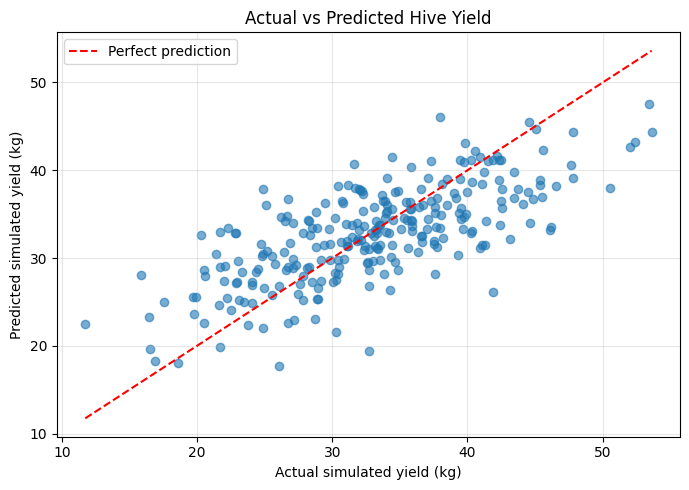

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_r, y_pred_r, alpha=0.6)
low = min(y_test_r.min(), y_pred_r.min())
high = max(y_test_r.max(), y_pred_r.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual simulated yield (kg)")
plt.ylabel("Predicted simulated yield (kg)")
plt.title("Actual vs Predicted Hive Yield")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Distribution of prediction errors

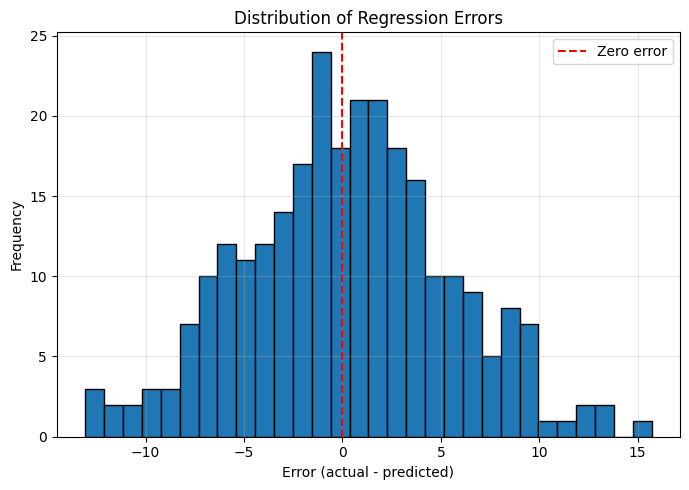

In [11]:
plt.figure(figsize=(7, 5))
plt.hist(errors, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Zero error")
plt.xlabel("Error (actual - predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Regression Errors")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Residuals vs predicted values

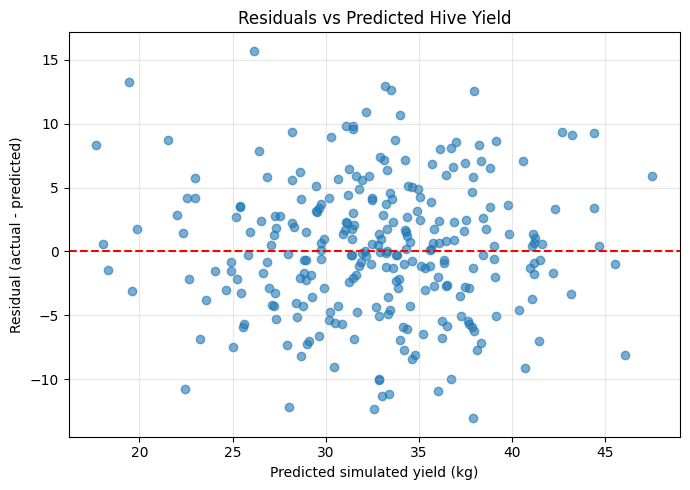

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(y_pred_r, errors, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted simulated yield (kg)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals vs Predicted Hive Yield")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Metric interpretation

- **Accuracy:** proportion of correctly classified hive observations.
- **Confusion matrix:** counts correct and incorrect predictions for each class.
- **Precision:** proportion of predicted stress observations that truly have the stress label.
- **Recall:** proportion of stress-labelled observations identified by the model.
- **ROC-AUC:** discrimination across classification thresholds; closer to 1 is generally better.
- **Log-loss:** evaluates probability quality; lower is better.
- **MAE/MAD:** average absolute difference between actual and predicted simulated yield.
- **R²:** fraction of target variation explained by the regression model; 1 is perfect, 0 is the test-set mean baseline, and negative values are possible.
- **Error distribution:** errors centered near zero without strong patterns are often desirable.

**Limitations:** all rows and labels are simulated. The notebook is for coursework and metric demonstrations, not real beekeeping or ecological decisions.